In [1]:
# Cell 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
# Cell 2: Load California Housing Dataset

data = fetch_california_housing(as_frame=True)

df = data.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Cell 3: Display Dataset Information

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
print(df.info())

print("\nFirst 5 Rows:")
print(df.head())

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None

First 5 Rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     3

In [4]:
# Cell 4: Check Missing Values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [5]:
# Cell 5: Create Categorical Feature

df["Income_Category"] = pd.cut(
    df["MedInc"],
    bins=[-np.inf, 2.5, 5.0, np.inf],
    labels=["Low", "Medium", "High"]
)

print("Categorical feature created successfully!")

print(df[["MedInc", "Income_Category"]].head(10))

Categorical feature created successfully!
   MedInc Income_Category
0  8.3252            High
1  8.3014            High
2  7.2574            High
3  5.6431            High
4  3.8462          Medium
5  4.0368          Medium
6  3.6591          Medium
7  3.1200          Medium
8  2.0804             Low
9  3.6912          Medium


In [6]:
# Cell 6: Separate Features and Target

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

Features shape: (20640, 9)
Target shape: (20640,)

Feature columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'Income_Category']

Target:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [7]:
# Cell 7: Identify Numerical and Categorical Features

numerical_features = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "Latitude",
    "Longitude"
]

categorical_features = [
    "Income_Category"
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Categorical Features:
['Income_Category']


In [8]:
# Cell 8: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (16512, 9)
Testing data shape: (4128, 9)


In [9]:
# Cell 9: Numerical Preprocessing

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


In [10]:
# Cell 10: Categorical Preprocessing

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


In [11]:
# Cell 11: Combine Numerical and Categorical Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [12]:
# Cell 12: Create Ridge Regression Model

ridge_model = Ridge(alpha=1.0)

print("Ridge Regression model created.")
print("Alpha:", ridge_model.alpha)

Ridge Regression model created.
Alpha: 1.0


In [13]:
# Cell 13: Complete Regression Pipeline

model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", ridge_model)
    ]
)

print("Complete pipeline created successfully!")

Complete pipeline created successfully!


In [14]:
# Cell 14: Train Ridge Regression Model

print("Training model...")

model_pipeline.fit(X_train, y_train)

print("Model trained successfully!")

Training model...
Model trained successfully!


In [15]:
# Cell 15: Make Predictions

y_pred = model_pipeline.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions generated successfully!

First 10 Actual Values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

First 10 Predicted Values:
[0.72443849 1.7955002  2.70782496 2.96760038 2.55357337 1.91376443
 2.82358955 2.13780557 2.63965129 3.9269677 ]


In [16]:
# Cell 16: Calculate R2 Score

r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.5768129820919785


In [17]:
# Cell 17: Calculate RMSE

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 0.7446798424434918


In [18]:
# Cell 18: Model Evaluation

print("========== MODEL EVALUATION ==========")
print(f"R² Score : {r2:.4f}")
print(f"RMSE     : {rmse:.4f}")
print("======================================")

========== MODEL EVALUATION ==========
R² Score : 0.5768
RMSE     : 0.7447


In [19]:
# Cell 19: Log Evaluation Metrics

metrics = pd.DataFrame({
    "Metric": ["R2 Score", "RMSE"],
    "Value": [r2, rmse]
})

print("Evaluation Metrics:")
print(metrics)

Evaluation Metrics:
     Metric     Value
0  R2 Score  0.576813
1      RMSE  0.744680


In [20]:
# Cell 20: Save Evaluation Metrics

metrics.to_csv("task2_evaluation_metrics.csv", index=False)

print("Evaluation metrics saved successfully!")
print("File: task2_evaluation_metrics.csv")

Evaluation metrics saved successfully!
File: task2_evaluation_metrics.csv


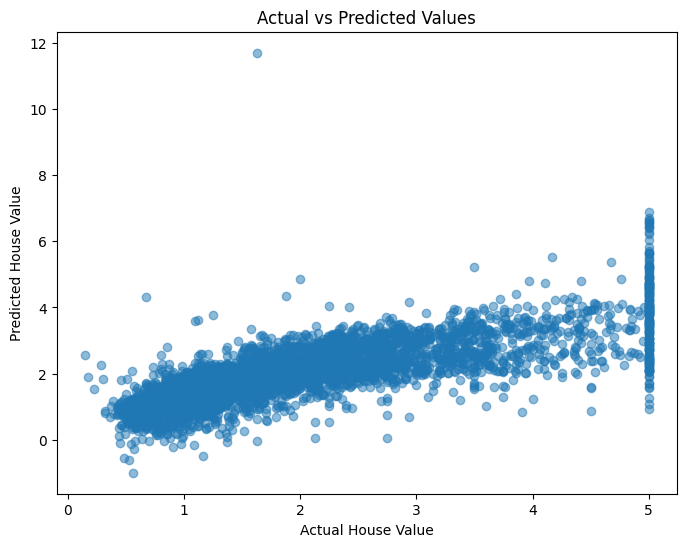

In [21]:
# Cell 21: Plot Actual vs Predicted Values

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted Values")

plt.show()

In [22]:
# Cell 22: Final Task Summary

print("========== TASK 2 COMPLETED ==========")

print("Dataset: California Housing")
print("Model: Ridge Regression")
print("Preprocessing:")
print("- Mean Imputation")
print("- Feature Scaling")
print("- Categorical Encoding")

print("\nEvaluation Metrics:")
print(f"R² Score = {r2:.4f}")
print(f"RMSE = {rmse:.4f}")

print("\nTask 2 completed successfully!")

========== TASK 2 COMPLETED ==========
Dataset: California Housing
Model: Ridge Regression
Preprocessing:
- Mean Imputation
- Feature Scaling
- Categorical Encoding

Evaluation Metrics:
R² Score = 0.5768
RMSE = 0.7447

Task 2 completed successfully!
